In [35]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_validate
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, recall_score
from sklearn.metrics import classification_report

from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import Normalizer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
import pandas as pd
import numpy as np
import os
#from aerosound.params import *
from keras import Sequential, layers
from keras.metrics import Recall
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam

In [3]:
def data_obtain_rnn(path):
# obtain data from the path and saperated the data by machine type and save the dataframes into a dictionary and return to this dictionary
    data_ori = pd.read_csv(path)
    # machine_dfs = {}

    # for machine in data_ori['machine'].unique():
    #     machine_dfs[machine] = data_ori[
    #         data_ori['machine'] == machine
    #     ].copy()

    # print(machine_dfs.keys())
    return data_ori

In [12]:
def prep_data_rnn(data_ori):
    scaler = StandardScaler()
    data = data_ori.copy()
    data = data.drop_duplicates()
    data['label'] = data['label'].map({
        'normal': 0,
        'abnormal': 1
    })
    data = data.drop(columns=['noise','machine','id','file','snr'])
    data = data.rename(columns={'label':'target'})
    X = data.drop(columns = 'target')
    y = data['target']

    X_trans = X.to_numpy().reshape(
        X.shape[0],
        X.shape[1]//2,
        2
    )

    #try: valuable!!!
    #X_train_rnn = X_train_rnn * 100
    X_trans_scaled = scaler.fit_transform(
        X_trans.reshape(-1, 2)
    ).reshape(X.shape[0], X.shape[1]//2, 2)

    # X_test_rnn = X_test.to_numpy().reshape(
    #     X_test.shape[0],
    #     X_test.shape[1],
    #     1
    # )
    return X_trans_scaled, y

In [17]:
def oversample_data(X_train, y_train):

    y_train = np.asarray(y_train).ravel()

    # Split training and validation data first
    # X_train, X_val, y_train, y_val = train_test_split(
    #     X, y,
    #     test_size=0.2,
    #     stratify=y,
    #     random_state=42
    # )

    # Oversample training data
    n_samples, n_steps, n_features = X_train.shape

    X_train_2d = X_train.reshape(n_samples, -1)

    ros = RandomOverSampler(
        sampling_strategy=1.0,
        random_state=42
    )

    X_resampled, y_resampled = ros.fit_resample(
        X_train_2d, y_train
    )

    # Restore 3D shape
    X_resampled = X_resampled.reshape(
        -1, n_steps, n_features
    )

    return X_resampled, y_resampled

In [5]:
def rnn_LSTM(X_train_rnn, X_val, y_train, y_val):
    ''' estublish the model, compile the model, train the model '''
    #estublish the model
    model = Sequential([
        layers.Input(shape=(X_train_rnn.shape[1],X_train_rnn.shape[2])),
        layers.LSTM(32),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])

    #compile the model
    model.compile(
        optimizer = Adam(learning_rate=0.0001, clipnorm=1.0),
        loss = 'binary_crossentropy',
        metrics=[
            Recall(name='recall'),
            'accuracy',
            'AUC'
        ]
    )

    #define early stop
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True
    )

    #add class weight for abnormal samples, because of unbalanced normal/abnormal data
    classes = np.unique(y_train)
    weights = compute_class_weight(
        class_weight='balanced',
        classes=classes,
        y=np.asarray(y_train)
    )
    class_weights = dict(zip(classes, weights))

    #train the model
    history = model.fit(
        X_train_rnn,
        y_train,
        epochs=500,
        batch_size=32,
        validation_data=(X_val, y_val),
        callbacks=[early_stop],
        class_weight=class_weights
    )
    return model, history

In [32]:
def predict_sound(model, X_pred):
    ''' predict normal/abnormal '''
    # X_pred_rnn = X_pred.reshape(
    #     X_pred.shape[0],
    #     X_pred.shape[1]//2,
    #     2
    # )
    X_pred_rnn = X_pred
    #X_pred_rnn = X_pred_rnn * 100
    scaler = StandardScaler()
    X_pred_rnn = scaler.fit_transform(
        X_pred_rnn.reshape(-1, 2)
    ).reshape(X_pred.shape[0], X_pred.shape[1], X_pred.shape[2])

    y = model.predict(X_pred_rnn)
    return (y >= 0.4).astype(int), y

In [ ]:
def model_evaluate(model, X_test, y_test):
    ''' show the performance of the model '''
    y_pred, y_prob_pred = predict_sound(model, X_test)

    y_true = np.asarray(y_test).ravel()
    y_pred = np.asarray(y_pred).ravel()
    y_prob_pred = np.asarray(y_prob_pred).ravel()

    auc = roc_auc_score(y_true, y_prob_pred)
    recall = recall_score(y_true, y_pred)

    print(f"Test AUC: {auc:.4f}")
    print(f"Test Recall: {recall:.4f}")

    #print(y_pred)
    #print(y_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred.ravel(),
        labels=[0,1],
        display_labels=["Normal", "Abnormal"]
    )

    plt.title("Confusion Matrix")
    plt.show()

In [8]:
print(os.getcwd())

/Users/shaotongwang/code/Marie-Jourdain/aerosound/aerosound/model


In [9]:
data_train = data_obtain_rnn('fan_all_train_stdzcr_100.csv')
data_val = data_obtain_rnn('fan_all_val_stdzcr_100.csv')
data_test = data_obtain_rnn('fan_all_test_stdzcr_100.csv')

In [10]:
data_train

,noise,machine,id,label,file,snr,f_000,f_001,f_002,f_003,...,f_190,f_191,f_192,f_193,f_194,f_195,f_196,f_197,f_198,f_199
0,-6_dB,dB_fan,id_00,abnormal,00000000.wav,-6,0.011441,0.080050,0.009736,0.095685,...,0.010477,0.082552,0.011197,0.076923,0.012078,0.064415,0.012113,0.069418,0.010662,0.088180
1,-6_dB,dB_fan,id_00,abnormal,00000006.wav,-6,0.011929,0.061288,0.014182,0.040025,...,0.010839,0.059412,0.013038,0.050657,0.015023,0.050031,0.012074,0.063164,0.013519,0.041901
2,-6_dB,dB_fan,id_00,abnormal,00000010.wav,-6,0.011440,0.061914,0.011594,0.065666,...,0.010713,0.088180,0.011881,0.081301,0.012925,0.083177,0.013544,0.089431,0.013099,0.081926
3,-6_dB,dB_fan,id_00,abnormal,00000016.wav,-6,0.013235,0.025016,0.012820,0.025641,...,0.010213,0.026266,0.010595,0.033146,0.011691,0.017511,0.011270,0.028768,0.011264,0.025641
4,-6_dB,dB_fan,id_00,abnormal,00000020.wav,-6,0.011455,0.066917,0.012531,0.066917,...,0.011697,0.069418,0.010888,0.080675,0.012445,0.086929,0.011725,0.080050,0.012543,0.083802
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9985,6_dB,dB_fan,id_06,normal,00000992.wav,6,0.005764,0.102564,0.005547,0.096936,...,0.005664,0.108193,0.006197,0.093809,0.006027,0.121951,0.005186,0.105691,0.006067,0.106942
9986,6_dB,dB_fan,id_06,normal,00000997.wav,6,0.005981,0.098812,0.005665,0.087555,...,0.006540,0.081926,0.006005,0.077548,0.005486,0.073171,0.006283,0.084428,0.006277,0.093183
9987,6_dB,dB_fan,id_06,normal,00001002.wav,6,0.005544,0.093183,0.005326,0.098186,...,0.005645,0.077548,0.005052,0.087555,0.004966,0.090682,0.004986,0.093183,0.005110,0.088180
9988,6_dB,dB_fan,id_06,normal,00001008.wav,6,0.005867,0.074422,0.007253,0.071920,...,0.006802,0.060663,0.006826,0.063164,0.006259,0.065666,0.006959,0.059412,0.006802,0.061288


In [13]:
X_train, y_train = prep_data_rnn(data_train)
X_val, y_val = prep_data_rnn(data_val)
X_test, y_test = prep_data_rnn(data_test)

In [18]:
X_train_resampled, y_train_resampled = oversample_data(X_train, y_train)

In [ ]:
# just for checking if the oversampling function works or not
y_resampled_df = pd.DataFrame(y_train_resampled.reshape(y_train_resampled.shape[0], -1))
print(y_resampled_df[0].value_counts(1))
print(y_resampled_df[0].value_counts(0))

0
1    0.5
0    0.5
Name: proportion, dtype: float64
0
1    7338
0    7338
Name: count, dtype: int64


In [21]:
rnn_model, history = rnn_LSTM(X_train_resampled, X_val, y_train_resampled, y_val)

Epoch 1/500
459/459 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - AUC: 0.5815 - accuracy: 0.5582 - loss: 0.6837 - recall: 0.4223 - val_AUC: 0.6573 - val_accuracy: 0.5982 - val_loss: 0.6833 - val_recall: 0.6282
Epoch 2/500
459/459 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - AUC: 0.6790 - accuracy: 0.6215 - loss: 0.6498 - recall: 0.6668 - val_AUC: 0.7146 - val_accuracy: 0.5868 - val_loss: 0.6200 - val_recall: 0.7288
Epoch 3/500
459/459 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - AUC: 0.7148 - accuracy: 0.6417 - loss: 0.6202 - recall: 0.7148 - val_AUC: 0.7209 - val_accuracy: 0.6186 - val_loss: 0.6143 - val_recall: 0.7062
Epoch 4/500
459/459 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - AUC: 0.7188 - accuracy: 0.6466 - loss: 0.6117 - recall: 0.6675 - val_AUC: 0.7267 - val_accuracy: 0.6300 - val_loss: 0.6022 - val_recall: 0.6949
Epoch 5/500
459/459 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - AUC: 0.7260 - accuracy: 0.6517 - loss: 0.6047 - recall: 0.6679 - val_AUC: 0.7328 - val_accuracy: 0.6453 - val_loss: 0.5994 - val_recall: 0.6847


In [22]:
rnn_model.save("lstm_stdzcr_allnoise_100_0.81_0.62.keras")

## visulize the result

105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


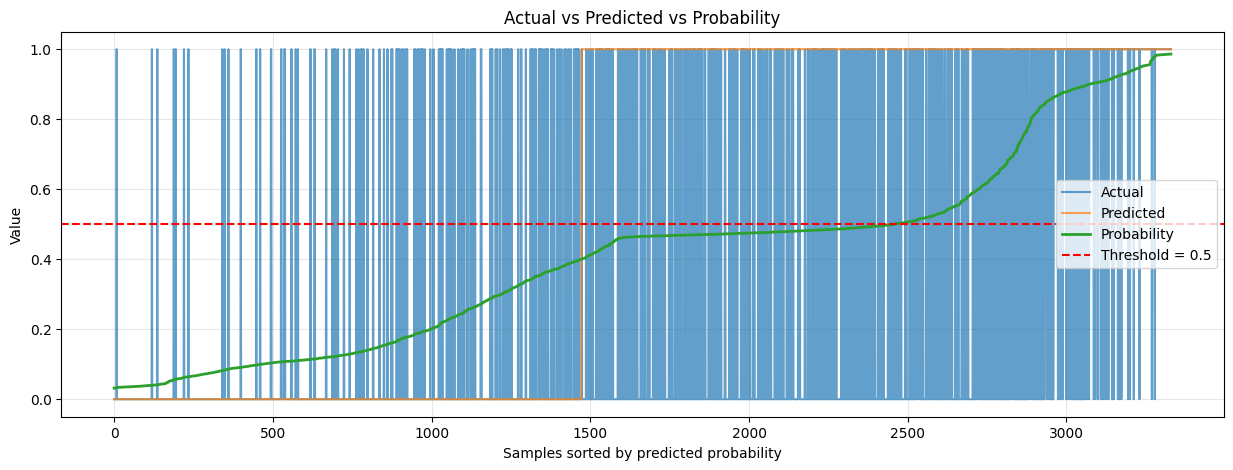

In [33]:
classified_pred, prob_pred = predict_sound(rnn_model, X_test)
y_test_plot = np.asarray(y_test).ravel()
y_pred_plot = np.asarray(classified_pred).ravel()
y_prob_plot = np.asarray(prob_pred).ravel()
visu = pd.DataFrame({'y_true':y_test_plot, 'y_pred':y_pred_plot, 'y_prob':y_prob_plot})
visu = visu.sort_values(by='y_prob').reset_index(drop=True)

# Plot
plt.figure(figsize=(15, 5))

plt.plot(visu['y_true'], label='Actual', alpha=0.7)
plt.plot(visu['y_pred'], label='Predicted', alpha=0.7)
plt.plot(visu['y_prob'], label='Probability', linewidth=2)

plt.axhline(0.5, color='red', linestyle='--', label='Threshold = 0.5')

plt.xlabel('Samples sorted by predicted probability')
plt.ylabel('Value')
plt.title('Actual vs Predicted vs Probability')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Test AUC: 0.7997
Test Recall: 0.8322


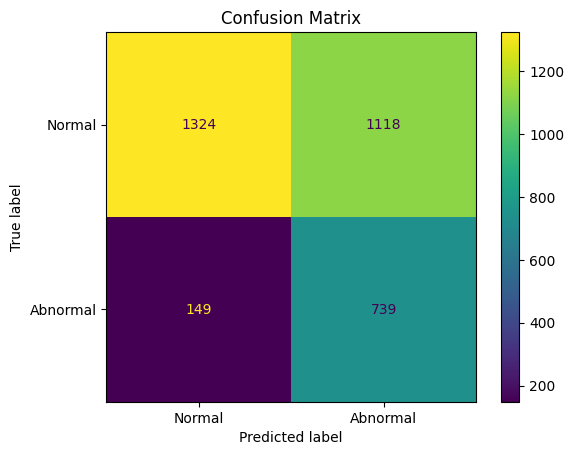

In [37]:
model_evaluate(rnn_model, X_test, y_test)